# K-Means Clustering for Image Segmentation
This notebook demonstrates how to use K-Means clustering to segment an image into different regions based on color.

In [1]:
# Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Step 1: Load and Resize the Image
We load the image and resize it to 256x256 pixels for simplicity.

In [2]:
# Load and resize image
img = cv2.imread('../dataset-min/Animals.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (256, 256))

## Step 2: Reshape the Image
Reshape the image into a 2D array of pixels for clustering.

In [3]:
# Reshape the image to a 2D array of pixels
pixel_values = img.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

## Step 3: Apply K-Means Clustering
Cluster the pixels into `k` clusters using the K-Means algorithm.

In [4]:
# Apply K-Means clustering
k = 4  # number of clusters
kmeans = KMeans(n_clusters=k, random_state=42)
labels = kmeans.fit_predict(pixel_values)

## Step 4: Reconstruct the Segmented Image
Replace each pixel with the color of its cluster center.

In [5]:
# Replace each pixel with its cluster center
centers = np.uint8(kmeans.cluster_centers_)
segmented_image = centers[labels.flatten()]
segmented_image = segmented_image.reshape(img.shape)

## Step 5: Evaluate Clustering Performance
We use the silhouette score and inter/intra-cluster distances to evaluate the clustering performance.
To speed up the computation, we sample a subset of the data.

In [6]:
# Evaluate clustering performance
from sklearn.utils import resample

# Sample 10,000 pixels for silhouette score computation
sampled_pixels, sampled_labels = resample(pixel_values, labels, n_samples=10000, random_state=42)

# Silhouette Score (only if there are clusters)
if len(set(sampled_labels)) > 1:
    silhouette_avg = silhouette_score(sampled_pixels, sampled_labels)
    print(f"Silhouette Score (sampled): {silhouette_avg:.2f}")
else:
    print("Silhouette Score cannot be calculated (only one cluster or noise).")

# Inter/Intra-cluster distances
intra_cluster_distances = np.mean([np.linalg.norm(pixel_values[labels == i] - center, axis=1).mean() for i, center in enumerate(kmeans.cluster_centers_)])
inter_cluster_distances = np.linalg.norm(kmeans.cluster_centers_[:, None] - kmeans.cluster_centers_, axis=2).mean()
print(f"Intra-cluster Distance: {intra_cluster_distances:.2f}")
print(f"Inter-cluster Distance: {inter_cluster_distances:.2f}")

Silhouette Score (sampled): 0.41
Intra-cluster Distance: 38.99
Inter-cluster Distance: 118.35


### Performance Metrics
To evaluate the clustering performance, we calculate the following metrics:
- **Silhouette Score**: Measures how similar a point is to its own cluster compared to other clusters.
- **Intra-cluster Distance**: Measures the compactness of clusters.
- **Inter-cluster Distance**: Measures the separation between clusters.

In [7]:
# Visualize silhouette score and distances
metrics = {
    'Silhouette Score': silhouette_avg if len(set(sampled_labels)) > 1 else None,
    'Intra-cluster Distance': intra_cluster_distances,
    'Inter-cluster Distance': inter_cluster_distances
}

for metric, value in metrics.items():
    if value is not None:
        print(f"{metric}: {value:.2f}")
    else:
        print(f"{metric}: Not applicable")

Silhouette Score: 0.41
Intra-cluster Distance: 38.99
Inter-cluster Distance: 118.35


### Visualizing Intermediate Results
Below are the intermediate clustering results for different values of `k`.

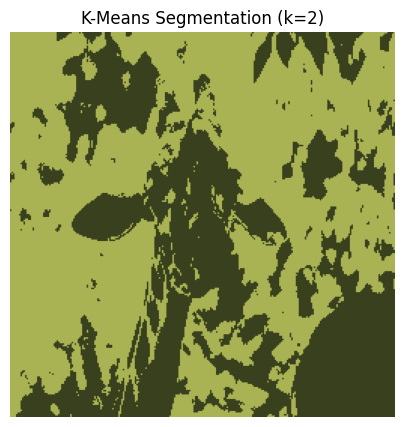

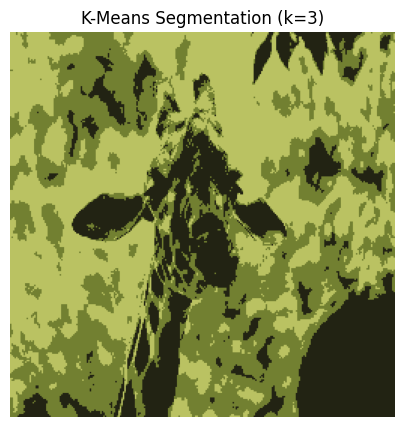

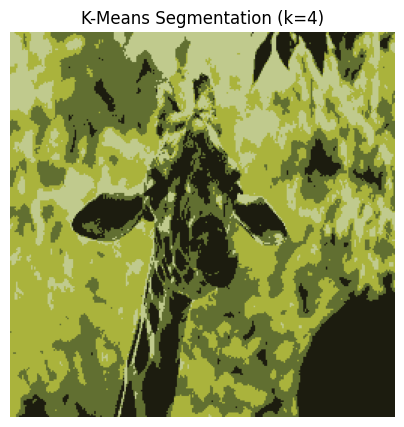

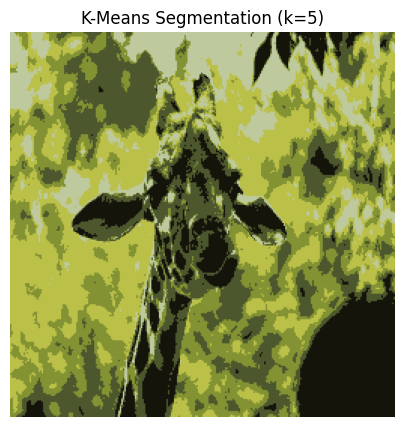

In [8]:
# Display intermediate clustering results
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(pixel_values)
    segmented_image = kmeans.cluster_centers_[labels.flatten()].reshape(img.shape)

    plt.figure(figsize=(5, 5))
    plt.title(f"K-Means Segmentation (k={k})")
    plt.imshow(segmented_image.astype(np.uint8))
    plt.axis('off')
    plt.show()